In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_result.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

# ── group num_of_neighbors into bins of 5 (1-5, 6-10, 11-15, …) ──────────────
BIN_SIZE = 5
max_neighbors = int(df['num_of_neighbors'].max())
bin_edges = list(range(0, max_neighbors + BIN_SIZE, BIN_SIZE))
NEIGHBOR_GROUPS = [f'{lo + 1}-{lo + BIN_SIZE}' for lo in bin_edges[:-1]]
df['neighbor_group'] = pd.cut(
    df['num_of_neighbors'], bins=bin_edges, labels=NEIGHBOR_GROUPS, right=True
)

def weighted_group_mean(frame: pd.DataFrame, value_col: str) -> pd.Series:
    """Mean of value_col per neighbour_group, weighted by num_of_neighbors."""
    def _wavg(g):
        mask = g[value_col].notna()
        if not mask.any():
            return np.nan
        return np.average(g.loc[mask, value_col], weights=g.loc[mask, 'num_of_neighbors'])
    return frame.groupby('neighbor_group', observed=True)[[value_col, 'num_of_neighbors']].apply(_wavg).reindex(NEIGHBOR_GROUPS)

print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)


945 rows  |  0 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error,neighbor_group
0,1089,2953793718,We deal with the \textit{selective classificat...,We propose a new approach to the problem of le...,0.3343,0.0616,0.2061,0.8333,0.8086,0.8208,2,3,6,69,False,66-70
1,1102,2958885478,Traditional 3D Convolutional Neural Networks (...,Convolutional neural networks (CNNs) have been...,0.3728,0.1114,0.2116,0.8711,0.8351,0.8528,2,7,7,50,False,46-50
2,1121,2964693852,Various formal languages have been proposed in...,This paper presents a new approach to the stud...,0.1462,0.0210,0.0940,0.7891,0.8437,0.8155,2,1,1,37,False,36-40


In [3]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour-count group (e.g. 1-5, 6-10, …)."""
    values = [series.get(g, np.nan) for g in NEIGHBOR_GROUPS]
    x = np.arange(len(NEIGHBOR_GROUPS))

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(x, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(NEIGHBOR_GROUPS, rotation=45, ha='right')
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


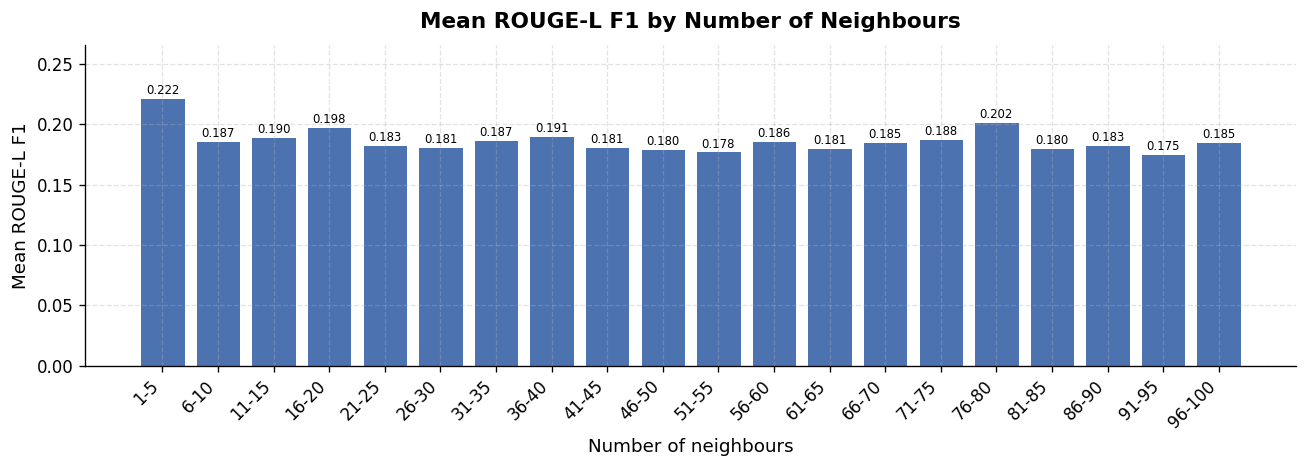

In [4]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = weighted_group_mean(df, 'rougeL_f')
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

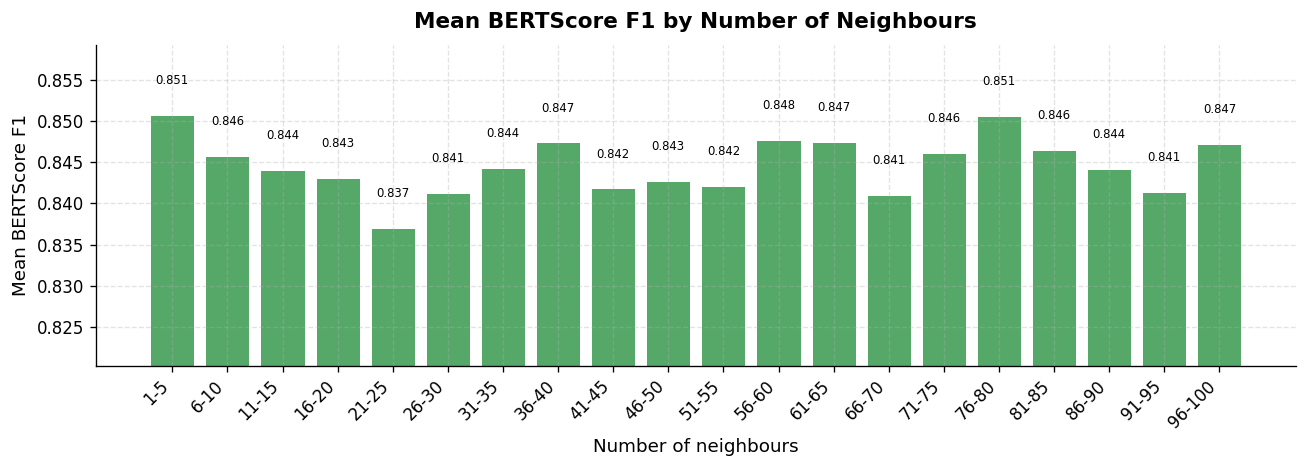

In [5]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = weighted_group_mean(df, 'bertscore_f1')
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

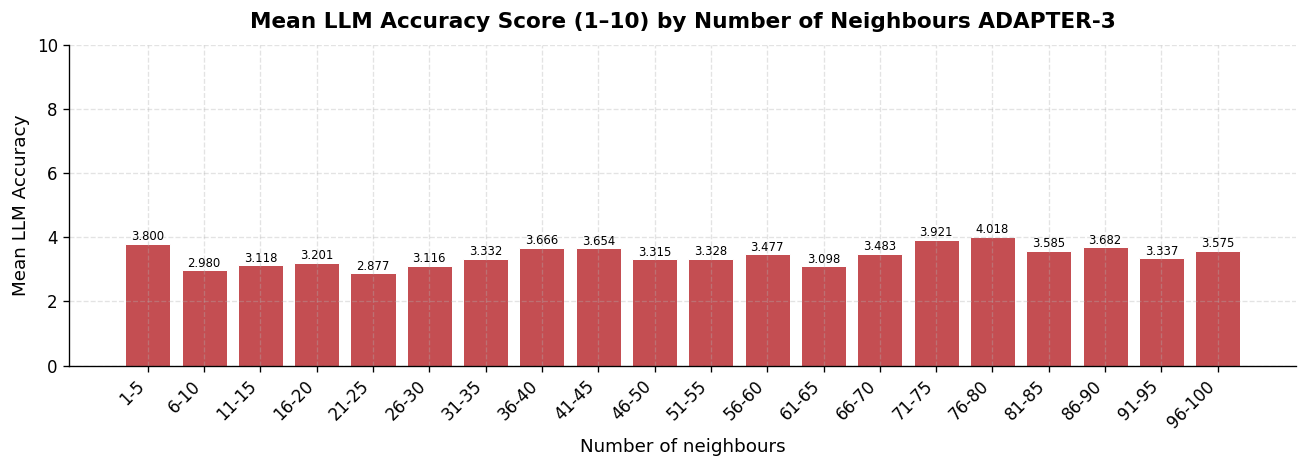

3.4074074074074074
3.0


In [6]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = weighted_group_mean(df, 'llm_accuracy')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

print(df['llm_accuracy'].mean())
print(df['llm_accuracy'].median())

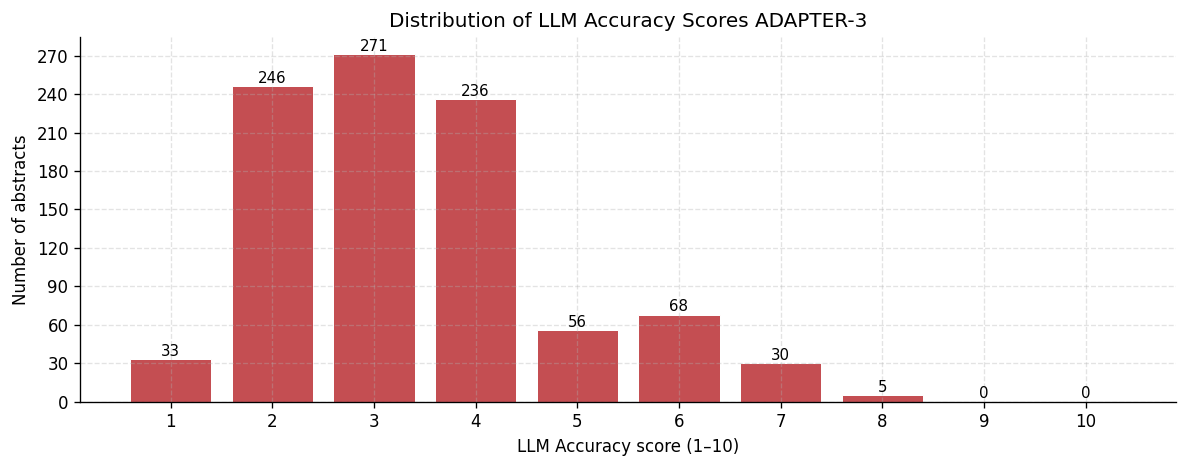

llm_accuracy
1      33
2     246
3     271
4     236
5      56
6      68
7      30
8       5
9       0
10      0
Name: count, dtype: int64

In [7]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_accuracy'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color='#C44E52',
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM Accuracy Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

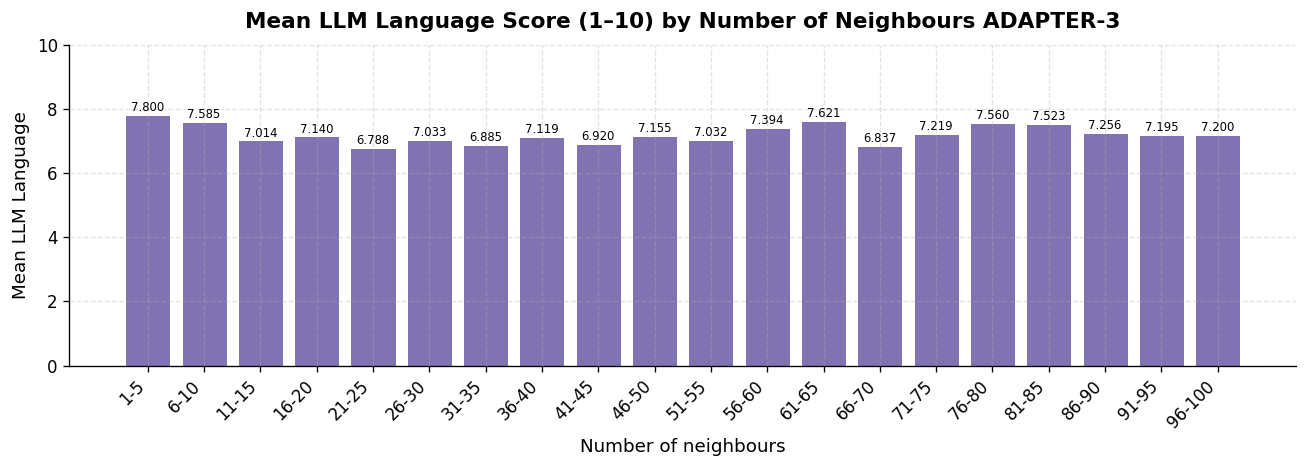

In [8]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = weighted_group_mean(df, 'llm_language')
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours ADAPTER-3',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

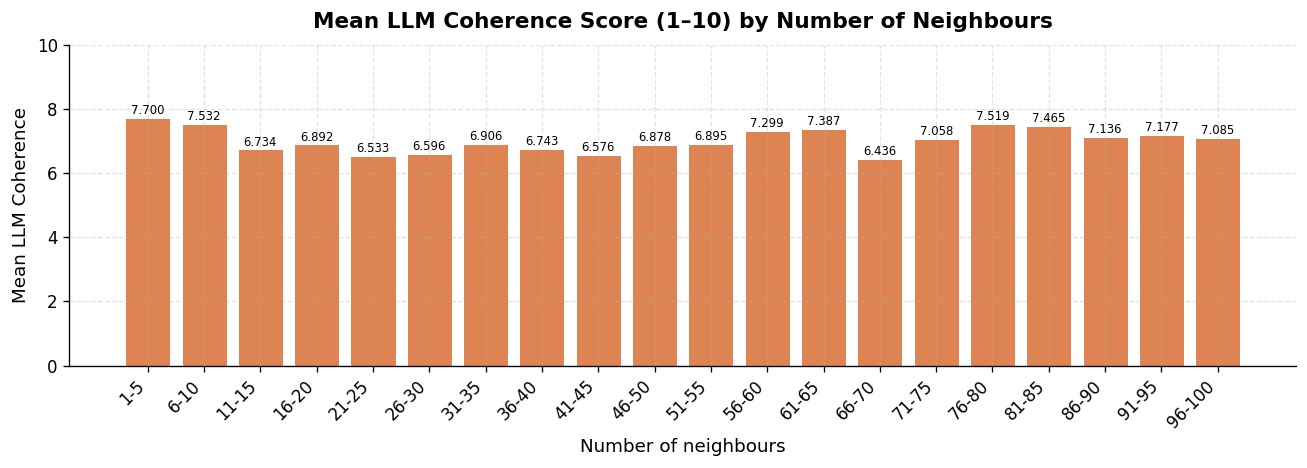

In [9]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = weighted_group_mean(df, 'llm_coherence')
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

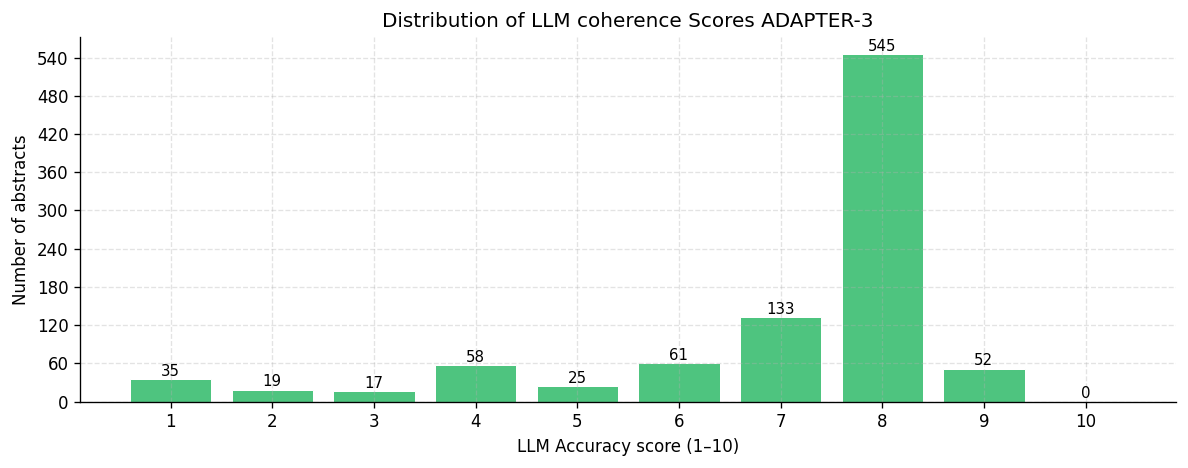

llm_coherence
1      35
2      19
3      17
4      58
5      25
6      61
7     133
8     545
9      52
10      0
Name: count, dtype: int64

In [10]:
# ── LLM Accuracy score distribution ───────────────────────────────────────────
SCORE_RANGE = list(range(1, 11))
acc_counts = (
    df['llm_coherence'].dropna().astype(int)
    .value_counts()
    .reindex(SCORE_RANGE, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(SCORE_RANGE, acc_counts.values, color="#4EC47F",
              edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, acc_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)

ax.set_title('Distribution of LLM coherence Scores ADAPTER-3')
ax.set_xlabel('LLM Accuracy score (1–10)')
ax.set_ylabel('Number of abstracts')
ax.set_xticks(SCORE_RANGE)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

acc_counts

In [11]:
# ── Mean llm_accuracy excluding low-coherence (1, 2) samples ─────────────────
filtered_df = df[~df['llm_coherence'].isin([1, 2])]

print(f'Excluded {len(df) - len(filtered_df)} rows with llm_coherence in [1, 2]')
print(f'Mean llm_accuracy (all rows):      {df["llm_accuracy"].mean():.4f}')
print(f'Mean llm_accuracy (excluding 1,2): {filtered_df["llm_accuracy"].mean():.4f}')


Excluded 54 rows with llm_coherence in [1, 2]
Mean llm_accuracy (all rows):      3.4074
Mean llm_accuracy (excluding 1,2): 3.4669


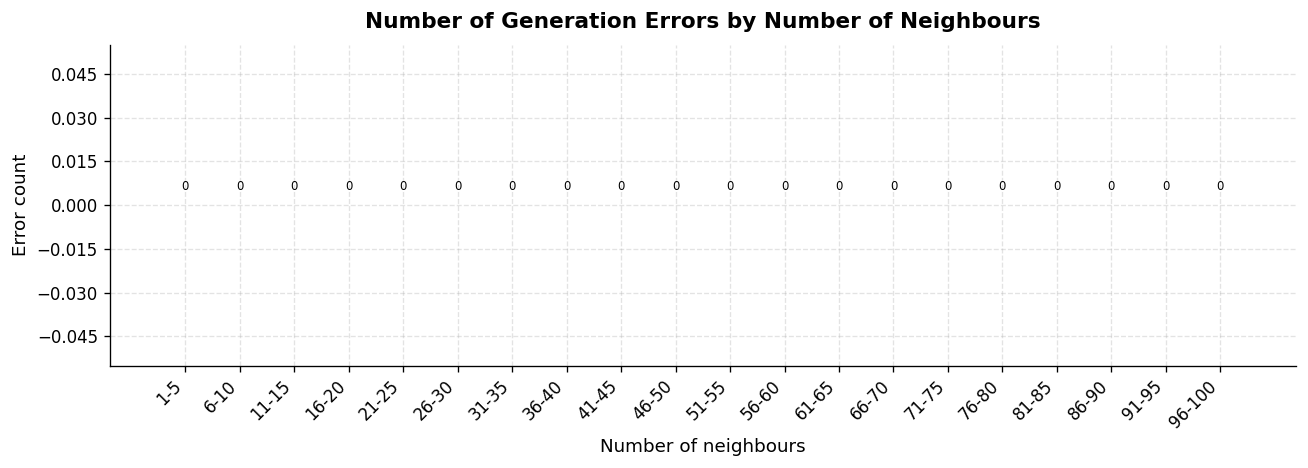

In [12]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('neighbor_group', observed=True).size().reindex(NEIGHBOR_GROUPS, fill_value=0)
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [13]:
# ── 5 examples each of llm_coherence score 1 and 2 ───────────────────────────
low_coherence_sample = (
    df[df['llm_coherence'].isin([1, 2])]
    .sort_values('llm_coherence')
    .groupby('llm_coherence', sort=True)
    .apply(lambda g: g.head(5))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_coherence']]
)

pd.set_option('display.max_colwidth', 2000)
low_coherence_sample


/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_20783/3088027966.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(5))


,node_id,original_abstract,generated_abstract,llm_coherence
0,1121,"Various formal languages have been proposed in the literature for the individual-based modelling of ecological systems. These languages differ in their treatment of time and space. Each modelling language offers a distinct view and techniques for analyzing systems. Most of the languages are based on process calculi or P systems. In this article, we present a general overview of the existing modelling languages based on process calculi. We also discuss, briefly, other approaches such as P systems, cellular automata and Petri nets. Finally, we show advantages and disadvantages of these modelling languages and we propose some future research directions.","This paper presents a new approach to the study of complex systems. The approach is based on the use of a formalism called the ""Membrane Calculus"" (MC). The MC is a formalism inspired by the biological membranes and their interactions. The MC is a variant of the well-known ""P systems"" formalism, which is a formalism inspired by the biological cells and their interactions. The MC is a formalism that is able to model the interactions between the membranes and the objects inside them. The MC is a formalism that is able to model the interactions between the membranes and the objects inside them. The MC is a formalism that is able to model the interactions between the membranes and the objects inside them. The MC is a formalism that is able to model the interactions between the membranes and the objects inside them. The MC is a formalism that is able to model the interactions between the membranes and the objects inside them. The MC is a formalism that is able to model the interactions between the membranes and the objects inside them. The MC is a formalism that is able to model the interactions between the membranes and the objects inside them. The MC is a formalism that is able to model the interactions between the membranes and the objects inside them. The MC is a formalism that is able to model the interactions between the membranes and the objects inside them. The MC is a formalism that is able to model the interactions between the membranes and the objects inside them. The MC is a formalism that is able to model the interactions between the membranes and the objects inside",1
1,85409,"Camera network and multi-camera calibration for external parameters is a necessary step for a variety of contexts in computer vision and robotics, ranging from three-dimensional reconstruction to human activity tracking. This paper describes a method for camera network and/or multi-camera calibration suitable for specific contexts: the cameras may not all have a common field of view, or if they do, there may be some views that are 180 degrees from one another, and the network may be asynchronous. The calibration object required is one or more planar calibration patterns, rigidly attached to one another, and are distinguishable from one another, such as aruco or charuco patterns. We formulate the camera network and/or multi-camera calibration problem in this context using rigidity constraints, represented as a system of equations, and an approximate solution is found through a two-step process. Synthetic and real experiments, including scenarios of a asynchronous camera network and rotating imaging system, demonstrate the method in a variety of settings. Reconstruction accuracy error was less than 0.5 mm for all datasets. This method is suitable for new users to calibrate a camera network, and the modularity of the calibration object also allows for disassembly, shipping, and the use of this method in a variety of large and small spaces.",We present a method for the calibration of a multi-camera system that is based on the relative motion of the cameras. The method is based on the calibration of the individual cameras and the estimation of the relative motion of the cameras. The calibration of the individual cameras is based on

In [14]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_20783/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,85903,"In this paper, we study normalization methods for neural networks from the perspective of elimination singularity. Elimination singularities correspond to the points on the training trajectory where neurons become consistently deactivated. They cause degenerate manifolds in the loss landscape which will slow down training and harm model performances. We show that channel-based normalizations (e.g. Layer Normalization and Group Normalization) are unable to guarantee a far distance from elimination singularities, in contrast with Batch Normalization which by design avoids models from getting too close to them. To address this issue, we propose BatchChannel Normalization (BCN), which uses batch knowledge to avoid the elimination singularities in the training of channel-normalized models. Unlike Batch Normalization, BCN is able to run in both large-batch and micro-batch training settings. The effectiveness of BCN is verified on many tasks, including image classification, object detection, instance segmentation, and semantic segmentation. The code is here: this https URL.","Batch normalization (BN) is a widely used technique for training deep neural networks. It has been shown that BN can be interpreted as a form of adaptive regularization. In this paper, we show that the adaptive regularization interpretation of BN is incomplete. We show that BN can be interpreted as a form of adaptive regularization that is applied to the input of each layer, and that the adaptive regularization is applied to the output of each layer. We show that the adaptive regularization applied to the output of each layer is a form of adaptive regularization that is applied to the output of each layer. We show that the adaptive regularization applied to the output of each layer is a form of adaptive regularization that is applied to the output of each layer. We show that the adaptive regularization applied to the output of each layer is a form of adaptive regularization that is applied to the output of each layer. We show that the adaptive regularization applied to the output of each layer is a form of adaptive regularization that is applied to the output of each layer. We show that the adaptive regularization applied to the output of each layer is a form of adaptive regularization that is applied to the output of each layer. We show that the adaptive regularization applied to the output of each layer is a form of adaptive regularization that is applied to the output of each layer. We show that the adaptive regularization applied to the output of each layer is a form of adaptive regularization that is applied to the output of each layer. We show that the adaptive regularization applied to the output of each layer is a form of adaptive regularization that is applied to the output of each layer. We show that",1
1,4664,"News headline generation is an essential problem of text summarization because it is constrained, well-defined, and is still hard to solve. Models with a limited vocabulary can not solve it well, as new named entities can appear regularly in the news and these entities often should be in the headline. News articles in morphologically rich languages such as Russian require model modifications due to a large number of possible word forms. This study aims to validate that models with a possibility of copying words from the original article performs better than models without such an option. The proposed model achieves a mean ROUGE score of 23 on the provided test dataset, which is 8 points greater than the result of a similar model without a copying mechanism. Moreover, the resulting model performs better than any known model on the new dataset of Russian news.","In this paper, we propose a novel method to improve the performance of neural machine translation (NMT) by introducing a new data augmentation method. We first generate a large number of new sentences by using a sentence e

In [15]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


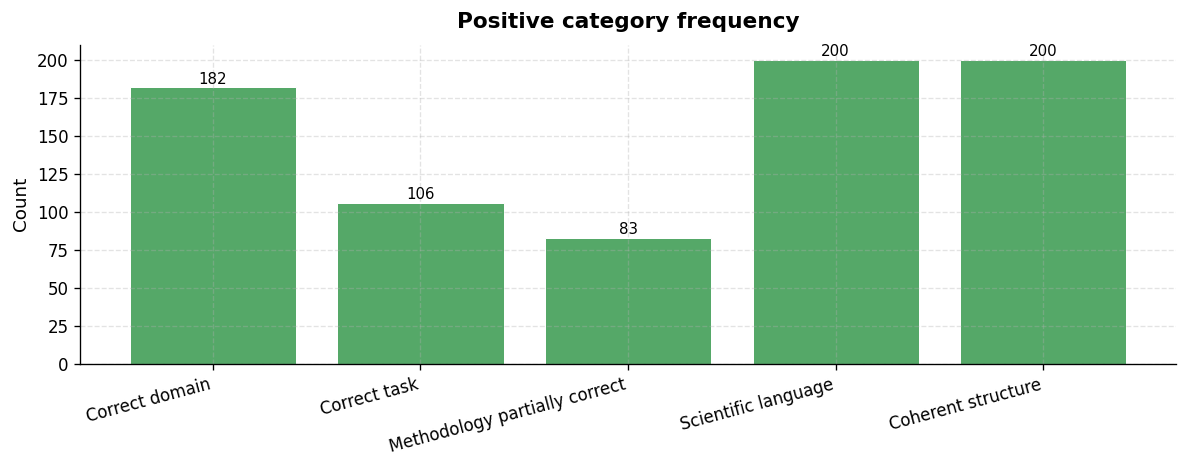

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()